# 10. Signal-free baseline (E0) and Figure 3

Signal-free baseline (SFB): accuracy from metadata only, weak estimator, out-of-fold, group-independent. Diagnostic item, not a necessary condition.

- Group held out: D1 site / D2 logger / D3 physical run
- In-sample lookup reported separately (memorisation ceiling)
- D3: hydrophone 120 (same rows as accuracy results) and all modalities 280
- Dependence: χ², Cramér's V, mutual information, max class-probability shift
- D3: permutation null of the metadata margin
- Accuracy: pooled OOF (correct / n); v1 fold-mean kept in `sfb_v1_foldmean`

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src as la
from src import config as cfg, io_utils, features, evaluation as ev, sfb, reporting as rp
cfg.apply_mpl_style(); cfg.banner()
rows, dep_rows = [], []

def record(dataset, task, predictor, protocol, y, fn, n_note="", clusters=None, unit="", **kw):
    """One SFB row: pooled OOF accuracy; cluster-bootstrap interval if `clusters` given."""
    
    y = np.asarray(y)
    acc_v1, pred = fn(return_pred=True)
    acc = float(np.mean(np.asarray(pred).astype(str) == y.astype(str))) if pred is not None else np.nan
    base = sfb.majority_baseline(y)
    if clusters is not None and pred is not None:
        ci = sfb.cluster_bootstrap_acc(np.asarray(pred).astype(str) == y.astype(str), clusters,
                                       n_boot=cfg.N_BOOT)
        kw.update(lo=ci["lo"], hi=ci["hi"], interval_unit=unit, n_groups=ci["n_clusters"])
    rows.append(dict(dataset=dataset, task=task, predictor=predictor, protocol=protocol,
                     sfb=acc, sfb_v1_foldmean=acc_v1, baseline=base, margin=acc - base,
                     n=len(y), note=n_note, **kw))
    print(f"  {dataset} {task:16s} {predictor:24s} {protocol:22s} n={len(y):<6d} "
          f"SFB={acc:.4f} base={base:.4f} margin={acc-base:+.4f}")
    return pred

LeakAudit | root=C:\Users\ecredible\Desktop\LeakAudit_revision1\LeakAudit | mode=FULL | seeds=10 | bootstrap=2000


## 1. D1 (AI-Hub)

- In-sample: sensor ID, site ID (ceiling)
- Site-independent (GroupKFold by site, 5 folds): sensor ID, lrate, llevel, acquisition date, all metadata
- Tasks: five-class, leak vs. non-leak, alarm vs. normal
- Official provider split rows: from notebook 02

In [2]:
X1, X1_max, M1, HZ = io_utils.load_d1()
y5 = M1.cls.to_numpy()
M1["date_ord"] = pd.to_datetime(M1.dt).map(lambda t: t.toordinal())
d1_tasks = {"5-class": y5,
            "leak/non-leak": np.where(np.isin(y5, ["out", "in"]), "leak", "nonleak"),
            "alarm/normal": np.where(y5 == "normal", "normal", "alarm")}
for task, yy in d1_tasks.items():
    print(f"\nD1 - {task}")
    record("D1", task, "sensor id", "in-sample (ceiling)", yy,
           lambda **k: sfb.sfb_categorical(M1.sid, yy, **k))
    record("D1", task, "site id", "in-sample (ceiling)", yy,
           lambda **k: sfb.sfb_categorical(M1.site, yy, **k))
    S1 = dict(clusters=M1.site, unit="site")
    record("D1", task, "sensor id", "site-independent", yy,
           lambda **k: sfb.sfb_categorical(M1.sid, yy, groups=M1.site, **k),
           n_note=("every test sensor is unseen, so the lookup falls back to the training-fold majority "
                   "class; its score depends only on how the class mix differs between sites"), **S1)
    record("D1", task, "lrate (device)", "site-independent", yy,
           lambda **k: sfb.sfb_numeric(M1.lrate, yy, groups=M1.site, **k), **S1)
    record("D1", task, "llevel (device)", "site-independent", yy,
           lambda **k: sfb.sfb_numeric(M1.llevel, yy, groups=M1.site, **k), **S1)
    record("D1", task, "acquisition date", "site-independent", yy,
           lambda **k: sfb.sfb_numeric(M1.date_ord, yy, groups=M1.site, max_depth=3, **k), **S1)
    record("D1", task, "all metadata", "site-independent", yy,
           lambda **k: sfb.sfb_multi(M1, yy, numeric_cols=["lrate", "llevel"],
                                     categorical_cols=["sid", "site"], groups=M1.site, **k),
           n_note="v1 definition: lrate, llevel, sensor and site codes; depth-3 tree", **S1)
    for col in ["sid", "site", "lrate"]:
        _, d = sfb.metadata_dependence(M1, col, yy)
        dep_rows.append(dict(dataset="D1", task=task, **d))

off = cfg.RESULTS / "E3_official_split.csv"
if off.exists():
    o = pd.read_csv(off)
    for _, r in o.iterrows():
        rows.append(dict(dataset="D1", task=r.task, predictor=r.predictor, protocol="official provider split",
                         sfb=r.sfb, sfb_v1_foldmean=np.nan, baseline=r.baseline,
                         margin=r.sfb - r.baseline, n=r.n, note="fitted on 'training', scored on 'validation'"))


D1 - 5-class
  D1 5-class          sensor id                in-sample (ceiling)    n=70384  SFB=1.0000 base=0.3149 margin=+0.6851
  D1 5-class          site id                  in-sample (ceiling)    n=70384  SFB=0.6550 base=0.3149 margin=+0.3401
  D1 5-class          sensor id                site-independent       n=70384  SFB=0.0852 base=0.3149 margin=-0.2297
  D1 5-class          lrate (device)           site-independent       n=70384  SFB=0.5953 base=0.3149 margin=+0.2803
  D1 5-class          llevel (device)          site-independent       n=70384  SFB=0.3938 base=0.3149 margin=+0.0788
  D1 5-class          acquisition date         site-independent       n=70384  SFB=0.4338 base=0.3149 margin=+0.1189
  D1 5-class          all metadata             site-independent       n=70384  SFB=0.5686 base=0.3149 margin=+0.2536

D1 - leak/non-leak
  D1 leak/non-leak    sensor id                in-sample (ceiling)    n=70384  SFB=1.0000 base=0.5075 margin=+0.4925
  D1 leak/non-leak    site id 

## 2. D2 (Hong Kong)

- Timed WAV (n = 118): recording hour (LOO, logger-independent), logger ID (ceiling), hour + material
- All WAV (n = 140): file naming, WAV header (sample rate + duration)
- Files with a date (n = 38): recording date (different class balance)

In [3]:
M2 = io_utils.scan_d2(audio_info=True)
d2 = M2[(M2.ext == ".wav") & (M2.label.isin(["leak", "noleak"]))].reset_index(drop=True)
d2["logger"] = d2.logger.fillna("NA")
sub = d2[d2.timed].reset_index(drop=True)
yb = sub.label.to_numpy()
print(f"D2 - leak vs no-leak (timed WAV files, n={len(sub)})")
record("D2", "leak/no-leak", "recording hour", "leave-one-out", yb,
       lambda **k: sfb.sfb_numeric(sub.hour, yb, **k), n_note="files of one logger on both sides")
record("D2", "leak/no-leak", "recording hour", "logger-independent", yb,
       lambda **k: sfb.sfb_numeric(sub.hour, yb, groups=sub.logger, **k),
       clusters=sub.logger, unit="logger")
record("D2", "leak/no-leak", "logger id", "in-sample (ceiling)", yb,
       lambda **k: sfb.sfb_categorical(sub.logger, yb, **k))
record("D2", "leak/no-leak", "hour + material", "logger-independent", yb,
       lambda **k: sfb.sfb_multi(sub, yb, numeric_cols=["hour"], categorical_cols=["material"],
                                 groups=sub.logger, **k), clusters=sub.logger, unit="logger")

ya = d2.label.to_numpy()
print(f"\nD2 - all WAV files (n={len(d2)})")
record("D2", "leak/no-leak", "file-naming convention", "logger-independent", ya,
       lambda **k: sfb.sfb_categorical(d2.naming, ya, groups=d2.logger, **k),
       n_note="NNN_LOGGER-YYYYMMDD files are all leak")
if "sr" in d2.columns and d2.sr.notna().any():
    d2["sr_dur"] = d2.sr.astype(str) + "_" + d2.duration_s.astype(float).round(0).astype(str)
    record("D2", "leak/no-leak", "sample rate + duration", "logger-independent", ya,
           lambda **k: sfb.sfb_categorical(d2.sr_dur, ya, groups=d2.logger, **k),
           n_note="WAV header only")
    _, d = sfb.metadata_dependence(d2, "sr_dur", ya); dep_rows.append(dict(dataset="D2", task="leak/no-leak", **d))
for col in ["naming", "material", "sensor"]:
    _, d = sfb.metadata_dependence(d2.astype(object).fillna("NA"), col, ya)
    dep_rows.append(dict(dataset="D2", task="leak/no-leak", **d))
_, d = sfb.metadata_dependence(sub.assign(hhmm=sub.hhmm.astype(str)), "hhmm", yb)
dep_rows.append(dict(dataset="D2", task="leak/no-leak (timed)", **d))

hasd = sub[sub.date.notna()].copy()
if len(hasd) > 20:
    hasd["date_ord"] = pd.to_datetime(hasd.date, format="%Y%m%d", errors="coerce").map(
        lambda t: t.toordinal() if pd.notna(t) else np.nan)
    yd = hasd.label.to_numpy()
    record("D2", "leak/no-leak", "recording date", "logger-independent", yd,
           lambda **k: sfb.sfb_numeric(hasd.date_ord.fillna(-1), yd, groups=hasd.logger, **k),
           n_note="subset with a date; different class balance - not comparable")

D2 - leak vs no-leak (timed WAV files, n=118)
  D2 leak/no-leak     recording hour           leave-one-out          n=118    SFB=0.8475 base=0.5932 margin=+0.2542
  D2 leak/no-leak     recording hour           logger-independent     n=118    SFB=0.8475 base=0.5932 margin=+0.2542
  D2 leak/no-leak     logger id                in-sample (ceiling)    n=118    SFB=1.0000 base=0.5932 margin=+0.4068
  D2 leak/no-leak     hour + material          logger-independent     n=118    SFB=0.8475 base=0.5932 margin=+0.2542

D2 - all WAV files (n=140)
  D2 leak/no-leak     file-naming convention   logger-independent     n=140    SFB=0.6000 base=0.5000 margin=+0.1000
  D2 leak/no-leak     sample rate + duration   logger-independent     n=140    SFB=0.6429 base=0.5000 margin=+0.1429
  D2 leak/no-leak     recording date           logger-independent     n=38     SFB=0.9211 base=0.7895 margin=+0.1316


C:\Users\ecredible\AppData\Local\Temp\ipykernel_13468\171773574.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _, d = sfb.metadata_dependence(d2.astype(object).fillna("NA"), col, ya)
C:\Users\ecredible\AppData\Local\Temp\ipykernel_13468\171773574.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _, d = sfb.metadata_dependence(d2.astype(object).fillna("NA"), col, ya)
C:\Users\ecredible\AppData\Local\Temp\ipykernel_13468\171773574.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a fu

## 3. D3 - Aghashahi testbed

- Fields: topology, flow, noise, sensor (+ modality for n = 280); leak type excluded (label)
- Protocols: in-sample, run-independent, v1 grouping (topology × leak type)
- Permutation null of the all-metadata margin (2,000 permutations)

In [4]:
M3 = io_utils.scan_d3()
all280 = M3[(~M3.is_bg) & M3.label.notna()].reset_index(drop=True)
hyd120 = all280[all280.modality == "hydrophone"].reset_index(drop=True)
for c_ in ["topology", "flow", "noise", "sensor", "modality"]:
    all280[c_] = all280[c_].astype(str); hyd120[c_] = hyd120[c_].astype(str)

perm_rows = []
for pop, d, cols in [("hydrophone recordings (n=120)", hyd120, ["topology", "flow", "noise", "sensor"]),
                     ("all modalities (n=280)", all280, ["topology", "flow", "noise", "sensor", "modality"])]:
    y3 = d.label.to_numpy()
    print(f"\nD3 - {pop}")
    for col in cols:
        record("D3", "leak/no-leak", col, "in-sample (ceiling)", y3,
               lambda **k: sfb.sfb_categorical(d[col], y3, **k), n_note=pop)
        _, dd = sfb.metadata_dependence(d, col, y3)
        dep_rows.append(dict(dataset="D3", task=pop, **dd))
    record("D3", "leak/no-leak", "all metadata", "in-sample (ceiling)", y3,
           lambda **k: sfb.sfb_multi(d, y3, categorical_cols=cols, **k), n_note=pop)
    record("D3", "leak/no-leak", "all metadata", "run-independent", y3,
           lambda **k: sfb.sfb_multi(d, y3, categorical_cols=cols, groups=d.run_id, **k), n_note=pop,
           clusters=d.run_id, unit="physical run")
    record("D3", "leak/no-leak", "all metadata", "v1 condition-independent", y3,
           lambda **k: sfb.sfb_multi(d, y3, categorical_cols=cols, groups=d.cond_topo_leak, **k),
           n_note=pop + "; v1 grouping (topology x leak type)")
    stat = lambda yy: sfb.sfb_multi(d, yy, categorical_cols=cols, max_depth=3) - sfb.majority_baseline(yy)
    res, null = sfb.permutation_null_margin(stat, y3, n_perm=cfg.N_PERM_CHEAP, seed=0)
    perm_rows.append(dict(population=pop, **res))
    print(f"  permutation null of the all-metadata margin: {res}")

sfb_tab = pd.DataFrame(rows)
sfb_tab.to_csv(cfg.RESULTS / "E0_signal_free_baseline.csv", index=False)
dep = pd.DataFrame(dep_rows)
dep.to_csv(cfg.RESULTS / "E0_metadata_dependence.csv", index=False)
pd.DataFrame(perm_rows).to_csv(cfg.RESULTS / "E0_D3_permutation_null.csv", index=False)
print("\nmetadata dependence (R2-7):")
print(dep[["dataset", "task", "field", "n", "levels", "chi2", "p", "cramers_v", "mutual_info_bits",
           "max_class_prob_shift"]].round(4).to_string(index=False))


D3 - hydrophone recordings (n=120)
  D3 leak/no-leak     topology                 in-sample (ceiling)    n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     flow                     in-sample (ceiling)    n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     noise                    in-sample (ceiling)    n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     sensor                   in-sample (ceiling)    n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     all metadata             in-sample (ceiling)    n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     all metadata             run-independent        n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  D3 leak/no-leak     all metadata             v1 condition-independent n=120    SFB=0.8000 base=0.8000 margin=+0.0000
  permutation null of the all-metadata margin: {'observed': -1.1102230246251565e-16, 'null_mean': -0.015433333333333417, 'null_q95': 0.0, 'null

## 4. SFB on a common protocol (Table 3, Figure 3)

Per benchmark: best group-independent SFB, majority rate, in-sample ceiling, acoustic model with the same grouping (notebooks 07, 08b)

In [5]:
def pick(ds, task, protocol_prefix, extra=None, n=None):
    q = sfb_tab[(sfb_tab.dataset == ds) & (sfb_tab.task == task) &
                sfb_tab.protocol.str.startswith(protocol_prefix) & sfb_tab.sfb.notna()]
    if extra is not None:
        q = q[q.note.str.contains(extra, regex=False)]
    if n is not None:                     # same rows as the acoustic comparison
        q = q[q.n == n]
    return q.loc[q.margin.idxmax()] if len(q) else None

inc = pd.read_csv(cfg.RESULTS / "E12_incremental_all.csv") if (cfg.RESULTS / "E12_incremental_all.csv").exists() else None
def acoustic(ds, task_contains, protocol_contains, feature_contains):
    if inc is None:
        return None
    q = inc[(inc.dataset == ds) & inc.task.str.contains(task_contains, regex=False)
            & inc.protocol.str.contains(protocol_contains, regex=False)
            & inc.feature_set.str.contains(feature_contains, regex=False)
            & ~inc.feature_set.str.contains("+", regex=False)]
    return q.loc[q.acc.idxmax()] if len(q) else None

head = []
spec = [("D1", "5-class", "site-independent", None, len(M1), ("D1", "T5", "site-grouped", "acoustic"), "sites"),
        ("D2", "leak/no-leak", "logger-independent", None, len(sub), ("D2", "leak", "timed118", ""), "loggers"),
        ("D3", "leak/no-leak", "run-independent", "n=120", len(hyd120), ("D3", "leak", "run-independent", "acoustic"), "runs")]
for ds, task, prot, extra, n_rows, ak, unit in spec:
    s = pick(ds, task, prot, extra, n_rows)
    ceil = sfb_tab[(sfb_tab.dataset == ds) & (sfb_tab.task == task) & (sfb_tab.n == n_rows) &
                   (sfb_tab.protocol == "in-sample (ceiling)")].sfb.max()
    a = acoustic(*ak)
    if ds == "D2" and inc is not None:
        q = inc[(inc.dataset == "D2") & inc.protocol.str.contains("timed118") &
                ~inc.feature_set.str.contains("clock")]
        a = q.loc[q.acc.idxmax()] if len(q) else None
    head.append(dict(dataset=ds, task=task, unit_held_out=unit, sfb_predictor=s.predictor,
                     sfb_protocol=s.protocol, sfb=s.sfb, majority=s.baseline, sfb_margin=s.margin,
                     sfb_lo=s.get("lo", np.nan), sfb_hi=s.get("hi", np.nan),
                     insample_ceiling=ceil, n=s.n,
                     acoustic_model=None if a is None else a.feature_set,
                     acoustic_acc=np.nan if a is None else a.acc,
                     acoustic_lo=np.nan if a is None else a.acc_lo,
                     acoustic_hi=np.nan if a is None else a.acc_hi))
head = pd.DataFrame(head)
head.to_csv(cfg.RESULTS / "E0_sfb_common_protocol.csv", index=False)
print(head.round(4).to_string(index=False))
la.save_json(head.to_dict(orient="records"), "E0_sfb_summary.json")
for _, r in head.iterrows():
    rp.record(f"{r.dataset}.SFB.common.{r.sfb_predictor}", r.sfb, "E0_sfb_common_protocol.csv", "R1-M1,R2-3",
              lo=None if pd.isna(r.sfb_lo) else r.sfb_lo, hi=None if pd.isna(r.sfb_hi) else r.sfb_hi,
              note=f"{r.sfb_protocol}; majority={r.majority:.4f}; margin={r.sfb_margin:+.4f}")
    rp.record(f"{r.dataset}.SFB.insample_ceiling", r.insample_ceiling, "E0_sfb_common_protocol.csv", "R1-M1")
    if pd.notna(r.acoustic_acc):
        rp.record(f"{r.dataset}.acoustic.same_grouping", r.acoustic_acc, "E0_sfb_common_protocol.csv", "R2-3",
                  lo=r.acoustic_lo, hi=r.acoustic_hi, note=str(r.acoustic_model))
for _, r in sfb_tab.iterrows():
    rp.record(f"{r.dataset}.SFB.table3.{r.task}.{r.predictor}.{r.protocol}", r.sfb, "E0_signal_free_baseline.csv",
              "R1-M1,R1-minor(Table3)", note=f"n={r.n}; base={r.baseline:.4f}")

dataset         task unit_held_out  sfb_predictor       sfb_protocol    sfb  majority  sfb_margin  sfb_lo  sfb_hi  insample_ceiling     n             acoustic_model  acoustic_acc  acoustic_lo  acoustic_hi
     D1      5-class         sites lrate (device)   site-independent 0.5953    0.3149      0.2803  0.4330  0.7422               1.0 70384         acoustic: 513 bins        0.5202       0.3680       0.6590
     D2 leak/no-leak       loggers recording hour logger-independent 0.8475    0.5932      0.2542  0.7187  0.9608               1.0   118                        AST        0.8619       0.7478       0.9445
     D3 leak/no-leak          runs   all metadata    run-independent 0.8000    0.8000      0.0000  0.7000  0.9000               0.8   120 acoustic: 199 mel features        0.9358       0.8997       0.9686


## 5. Figure 3

saved figures/Fig3_signal_free_baseline.png and .pdf (600 dpi, greyscale)


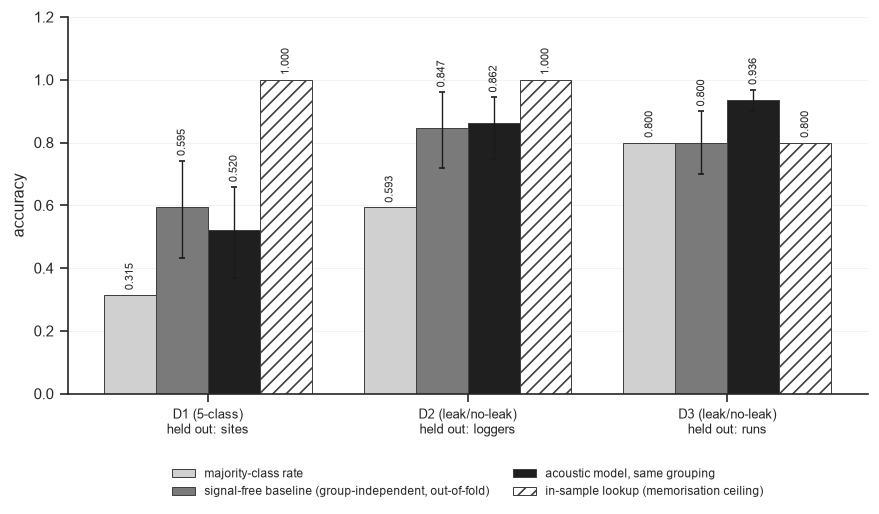

In [6]:
import seaborn as sns
cfg.apply_mpl_style()
G = cfg.GREYS
QN = {"majority": "majority-class rate",
      "sfb": "signal-free baseline (group-independent, out-of-fold)",
      "acoustic_acc": "acoustic model, same grouping",
      "insample_ceiling": "in-sample lookup (memorisation ceiling)"}
head["bench"] = [f"{r.dataset} ({r.task})\nheld out: {r.unit_held_out}" for _, r in head.iterrows()]
long = head.melt(id_vars="bench", value_vars=list(QN), var_name="q", value_name="acc")
long["quantity"] = long.q.map(QN)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
sns.barplot(data=long, x="bench", y="acc", hue="quantity", hue_order=list(QN.values()),
            palette=[G[1], G[3], G[5], "white"], edgecolor="0.25", linewidth=0.6, ax=ax)
nb, nq = len(head), len(QN)
w = 0.8 / nq
for j, (col, (lo_c, hi_c)) in enumerate(zip(QN, [(None, None), ("sfb_lo", "sfb_hi"),
                                                 ("acoustic_lo", "acoustic_hi"), (None, None)])):
    pos = np.arange(nb) - 0.4 + w * (j + 0.5)
    vals = head[col].to_numpy(float)
    tops = vals.copy()
    if lo_c is not None:
        lo, hi = head[lo_c].to_numpy(float), head[hi_c].to_numpy(float)
        ok = np.isfinite(lo) & np.isfinite(vals)
        ax.errorbar(pos[ok], vals[ok], yerr=[vals[ok] - lo[ok], hi[ok] - vals[ok]], fmt="none",
                    ecolor="0.1", capsize=2, lw=0.8)
        tops = np.fmax(vals, hi)
    for x_, v, tp in zip(pos, vals, tops):
        if np.isfinite(v):
            ax.text(x_, tp + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=6.8, rotation=90)
for patch in ax.patches[3 * nb:4 * nb]:            # memorisation-ceiling bars hatched
    patch.set_hatch("///")
ax.set_xlabel(""); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.2)
ax.tick_params(axis="x", labelsize=8)
leg = ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, title=None)
leg.legend_handles[3].set_hatch("///")
ax.grid(False, axis="x"); sns.despine(ax=ax)
fig.tight_layout()
cfg.save_figure(fig, "Fig3_signal_free_baseline")
head.to_csv(cfg.RESULTS / "fig3_data.csv", index=False)
plt.show()